# Dataset Integrity Audit

I audit the original APTOS split before interpreting the final results. The audit reads all 3,662 files without changing images, labels, or historical checkpoints.

The checks cover missing/corrupt images, grade validity, repeated identifiers, file and decoded-RGB SHA-256 duplicates, and cross-split perceptual-hash candidates (63 DCT bits, Hamming distance <= 4). Similarity candidates are not confirmed duplicates. Patient independence cannot be established from CSVs containing only image IDs and grades.

Select the project `.venv` kernel and run the cells in order. This notebook does not train a model.


In [1]:
from pathlib import Path
import os
import sys

project_root = next(
    (p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
     if (p / "src/dr_detection").is_dir() and (p / "configs").is_dir()),
    None,
)
if project_root is None:
    raise RuntimeError("Open this notebook inside the project folder.")
sys.path.insert(0, str(project_root / "src"))
os.environ.setdefault("MPLCONFIGDIR", str(project_root / ".mplconfig"))

import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image as DisplayImage

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print(f"Project: {project_root}")


Project: /Users/berekebaimuratov/Desktop/Detection of Diabetic Retinopathy


## 1. Audit every image

This cell performs a fresh scan. Exact duplicates are identified from decoded RGB pixels including image dimensions; file hashes distinguish byte-identical copies from re-encoded copies.


In [2]:
from dr_detection.audit import run_audit

audit = run_audit(project_root)
output_dir = project_root / "outputs/data_audit"
print(f"Audit status: {audit['status']}")
print(f"Full results: {output_dir}")


Audit images:   0%|          | 0/3662 [00:00<?, ?it/s]

Audit images:   6%|▌         | 227/3662 [00:05<01:15, 45.23it/s]

Audit images:  13%|█▎        | 475/3662 [00:10<01:06, 47.65it/s]

Audit images:  20%|█▉        | 726/3662 [00:15<01:00, 48.66it/s]

Audit images:  27%|██▋       | 990/3662 [00:20<00:53, 50.11it/s]

...

Audit images:  84%|████████▍ | 3089/3662 [01:01<00:11, 50.16it/s]

Audit images:  91%|█████████ | 3341/3662 [01:06<00:06, 49.80it/s]

Audit images:  98%|█████████▊| 3596/3662 [01:11<00:01, 50.00it/s]

Audit images: 100%|██████████| 3662/3662 [01:12<00:00, 50.49it/s]

Audit status: issues_found
Full results: /Users/berekebaimuratov/Desktop/Detection of Diabetic Retinopathy/outputs/data_audit


**Table 18.1. Complete image manifest (first ten records displayed)**


In [3]:
manifest = pd.read_csv(output_dir / "table_18_1_image_manifest.csv", dtype={"phash": str})
display(manifest.head(10))


,split,id_code,diagnosis,image_path,status,error,file_sha256,pixel_sha256,phash,width,height,valid_label,binary_label
0,train,1ae8c165fd53,2,data/raw/aptos2019/train_images/train_images/1...,ok,NaN,4134302dbbef870030a6061212f7c56f31f08def634839...,6c6a48205ba07fb3e01ee5d3da5f86fd1a86d3f3464138...,312d56be527d44d0,3216,2136,True,1
1,train,1b329a127307,1,data/raw/aptos2019/train_images/train_images/1...,ok,NaN,a30d9ed1f2ead0aa5692c547d0e41ff7a572996250cd06...,41f51416d66c05e4b8d958729e8de3d4c40d4711c34975...,337d7bfa63004485,2588,1958,True,1
2,train,1b32e1d775ea,4,data/raw/aptos2019/train_images/train_images/1...,ok,NaN,67b649be0d71f66e995d061dfbef2d37102030c6dbbe8e...,2fa1d81b49e7222a860585e4bae60a14d34e4b96ea97e7...,71eb10bc51f856c1,1504,1000,True,1
3,train,1b3647865779,0,data/raw/aptos2019/train_images/train_images/1...,ok,NaN,e4a5d10f80bc3bcce9fc515f2f651be5d9cf164a97e31e...,c636b2e7c7a6ad182e581894a5157deb4c23da9bc5d300...,6b0736966ccb1334,819,614,True,0
4,train,1b398c0494d1,0,data/raw/aptos2019/train_images/train_images/1...,ok,NaN,73d391cb437861b073d02c76efe954660d93d9ac701374...,8d9004ceb19d7af13a6a974d9a5a440b84f6e6dab29ca0...,292b5a7a2da954d4,1050,1050,True,0
5,train,1b4625877527,2,data/raw/aptos2019/train_images/train_images/1...,ok,NaN,3f2cc0e09062f4dd6b37a256849ef54fcfc39c45ca5f32...,62afb68b7ec9c38aa787372884aeeab480bfac05014c90...,363c51e9533c4b54,1504,1000,True,1
6,train,1b495ac025b7,3,data/raw/aptos2019/train_images/train_images/1...,ok,NaN,96c6bcc5d796508879ecd04edf975a77a7a15ab9c85955...,235da28b91c07b97ae557198b16d85c08ccd16b64567d0...,7c3db37807745481,2416,1736,True,1
7,train,1b862fb6f65d,0,data/raw/aptos2019/train_images/train_images/1...,ok,NaN,9e67e043c5236a0a30cf3b2411285e68734d2c2ec816a6...,f197bcd84c07cb9d344f19e346c672a1ae2844423bb50d...,293e56fa292954d4,1050,1050,True,0
8,train,1b8701231c8f,0,data/raw/aptos2019/train_images/train_images/1...,ok,NaN,b7c5b5eda9b516c756f29a9abe4042b51268636916d29a...,b8297faa07f5d28f82c05966fc12908aa0f6807278b119...,736b31be41e91494,819,614,True,0
9,train,1b8ad0afe9fb,2,data/raw/aptos2019/train_images/train_images/1...,ok,NaN,119ad16e51e14bb906f6acb38f0e2c3c5210693917dbf3...,4f4cafc0237821747f4de9d284f25f9e3080ab33053427...,3e3e61e31c9c51d0,2588,1958,True,1


**Table 18.2. Original severity labels by split**


In [4]:
distribution = pd.read_csv(output_dir / "table_18_2_grade_distribution.csv").set_index("split")
display(distribution)


,0,1,2,3,4
split,,,,,
train,1434,300,808,154,234
valid,172,40,104,22,28
test,199,30,87,17,33


**Figure 18.1. Severity distribution within each original split**


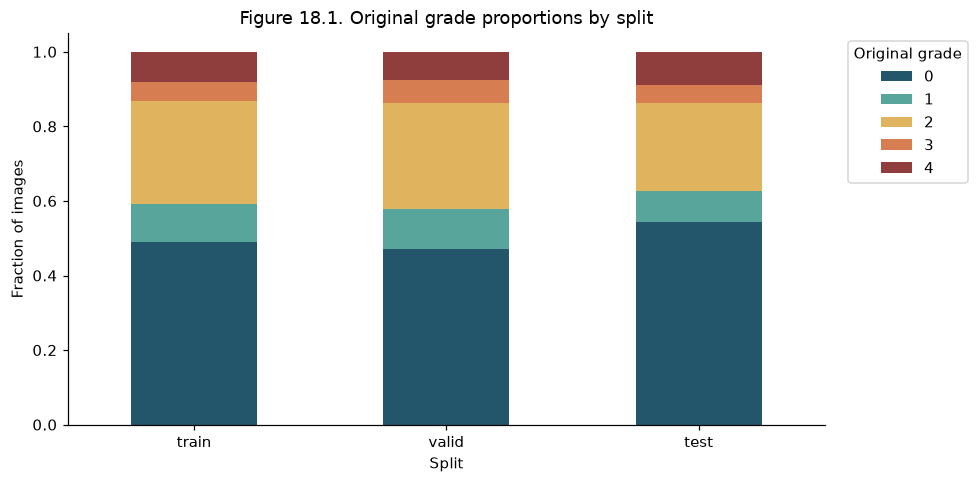

In [5]:
fractions = distribution.div(distribution.sum(axis=1), axis=0)
ax = fractions.plot.bar(stacked=True, figsize=(9, 4.5), color=["#24566b", "#58a59c", "#e0b45f", "#d67e52", "#903d3e"])
ax.set(title="Figure 18.1. Original grade proportions by split", xlabel="Split", ylabel="Fraction of images")
ax.legend(title="Original grade", bbox_to_anchor=(1.02, 1))
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(output_dir / "figure_18_1_grade_distribution.png", dpi=200, bbox_inches="tight")
plt.show()


**Tables 18.3-18.5. Identifier matches, exact duplicate pairs, and similarity candidates**

The tables below display previews; their CSV files contain every match. A pair count is not a count of unique images.


In [6]:
ids = pd.read_csv(output_dir / "table_18_3_repeated_ids.csv")
exact = pd.read_csv(output_dir / "table_18_4_exact_duplicate_pairs.csv")
similar = pd.read_csv(output_dir / "table_18_5_similar_cross_split_candidates.csv")
for caption, frame in [("Table 18.3. Repeated IDs", ids), ("Table 18.4. Exact pairs", exact), ("Table 18.5. Similarity candidates", similar)]:
    display(Markdown(f"**{caption}**"))
    display(frame.head(10))


**Table 18.3. Repeated IDs**

,id_code,records,splits,cross_split


**Table 18.4. Exact pairs**

,split_a,id_a,diagnosis_a,path_a,split_b,id_b,diagnosis_b,path_b,match_type,hamming_distance
0,train,a505981d1cab,2,data/raw/aptos2019/train_images/train_images/a...,train,d994203deb64,2,data/raw/aptos2019/train_images/train_images/d...,identical_file,0
1,train,1cb814ed6332,2,data/raw/aptos2019/train_images/train_images/1...,train,a7b0d0c51731,2,data/raw/aptos2019/train_images/train_images/a...,identical_file,0
2,train,9a3c03a5ad0f,2,data/raw/aptos2019/train_images/train_images/9...,test,f03d3c4ce7fb,4,data/raw/aptos2019/test_images/test_images/f03...,identical_file,0
3,train,cd3fd04d72f5,2,data/raw/aptos2019/train_images/train_images/c...,train,d81b6ed83bc2,2,data/raw/aptos2019/train_images/train_images/d...,identical_file,0
4,train,9b7b6e4db1d5,2,data/raw/aptos2019/train_images/train_images/9...,train,9f4132bd6ed6,2,data/raw/aptos2019/train_images/train_images/9...,identical_file,0
5,train,80d24897669f,1,data/raw/aptos2019/train_images/train_images/8...,test,fea14b3d44b0,1,data/raw/aptos2019/test_images/test_images/fea...,identical_file,0
6,train,ce887b196c23,2,data/raw/aptos2019/train_images/train_images/c...,test,e7a7187066ad,2,data/raw/aptos2019/test_images/test_images/e7a...,identical_file,0
7,train,7e160c8b611e,3,data/raw/aptos2019/train_images/train_images/7...,train,91b6ebaa3678,3,data/raw/aptos2019/train_images/train_images/9...,identical_file,0
8,train,d28bd830c171,2,data/raw/aptos2019/train_images/train_images/d...,test,f9ecf1795804,2,data/raw/aptos2019/test_images/test_images/f9e...,identical_file,0
9,train,1e8a1fdee5b9,1,data/raw/aptos2019/train_images/train_images/1...,train,a47432cd41e7,1,data/raw/aptos2019/train_images/train_images/a...,identical_file,0


**Table 18.5. Similarity candidates**

,split_a,id_a,diagnosis_a,path_a,split_b,id_b,diagnosis_b,path_b,match_type,hamming_distance
0,train,1b862fb6f65d,0,data/raw/aptos2019/train_images/train_images/1...,valid,0a4e1a29ffff,0,data/raw/aptos2019/val_images/val_images/0a4e1...,perceptual_candidate,0
1,train,3b018e8b7303,3,data/raw/aptos2019/train_images/train_images/3...,valid,0243404e8a00,4,data/raw/aptos2019/val_images/val_images/02434...,perceptual_candidate,0
2,train,3ddb86eb530e,2,data/raw/aptos2019/train_images/train_images/3...,valid,0243404e8a00,4,data/raw/aptos2019/val_images/val_images/02434...,perceptual_candidate,0
3,train,4d9fc85a8259,3,data/raw/aptos2019/train_images/train_images/4...,valid,16ce555748d8,4,data/raw/aptos2019/val_images/val_images/16ce5...,perceptual_candidate,0
4,train,772af553b8b7,3,data/raw/aptos2019/train_images/train_images/7...,test,fcc6aa6755e6,3,data/raw/aptos2019/test_images/test_images/fcc...,perceptual_candidate,0
5,train,8273fdb4405e,1,data/raw/aptos2019/train_images/train_images/8...,test,f0098e9d4aee,4,data/raw/aptos2019/test_images/test_images/f00...,perceptual_candidate,0
6,train,de55ed25e0e8,0,data/raw/aptos2019/train_images/train_images/d...,test,ec6f1797a25a,0,data/raw/aptos2019/test_images/test_images/ec6...,perceptual_candidate,0
7,train,1d3e9b939732,0,data/raw/aptos2019/train_images/train_images/1...,valid,08f8838d69bb,0,data/raw/aptos2019/val_images/val_images/08f88...,perceptual_candidate,2
8,train,260a455692b5,0,data/raw/aptos2019/train_images/train_images/2...,valid,0d8f60ed9280,0,data/raw/aptos2019/val_images/val_images/0d8f6...,perceptual_candidate,2
9,train,3325b1fe55d2,0,data/raw/aptos2019/train_images/train_images/3...,valid,15e24b73d4a7,0,data/raw/aptos2019/val_images/val_images/15e24...,perceptual_candidate,2


**Table 18.6. Audit findings**


In [7]:
checks = pd.DataFrame([
    ("Missing files", audit["missing_images"]),
    ("Unreadable files", audit["unreadable_images"]),
    ("Invalid original grades", audit["invalid_labels"]),
    ("Repeated ID groups", audit["repeated_id_groups"]),
    ("Exact duplicate pairs, all splits", audit["exact_duplicate_pairs"]),
    ("Exact duplicate pairs across splits", audit["exact_cross_split_pairs"]),
    ("Test images matching train or validation", len(audit["test_images_matching_train_or_valid"])),
    ("Exact pairs with different original grades", audit["exact_duplicate_grade_conflicts"]),
    ("Exact pairs with different binary labels", audit["exact_duplicate_binary_conflicts"]),
    ("Cross-split binary-label conflicts", audit["exact_cross_split_binary_conflicts"]),
    ("Perceptual candidates requiring review", audit["similar_cross_split_candidates"]),
], columns=["check", "count"])
checks.to_csv(output_dir / "table_18_6_audit_findings.csv", index=False)
display(checks)


,check,count
0,Missing files,0
1,Unreadable files,0
2,Invalid original grades,0
3,Repeated ID groups,0
4,"Exact duplicate pairs, all splits",134
5,Exact duplicate pairs across splits,47
6,Test images matching train or validation,24
7,Exact pairs with different original grades,32
8,Exact pairs with different binary labels,4
9,Cross-split binary-label conflicts,2


**Table 18.7. Exact duplicate pairs between splits**


In [8]:
cross = exact.loc[exact["split_a"] != exact["split_b"]]
cross_summary = cross.groupby(["split_a", "split_b"]).size().reset_index(name="pairs")
cross_summary.to_csv(output_dir / "table_18_7_cross_split_pairs.csv", index=False)
display(cross_summary)


,split_a,split_b,pairs
0,train,test,23
1,train,valid,22
2,valid,test,2


**Image 18.1. Cross-split exact duplicates with conflicting binary labels**

All such pairs are shown. The annotations disagree even though image content is identical; this notebook does not choose a medically correct label.


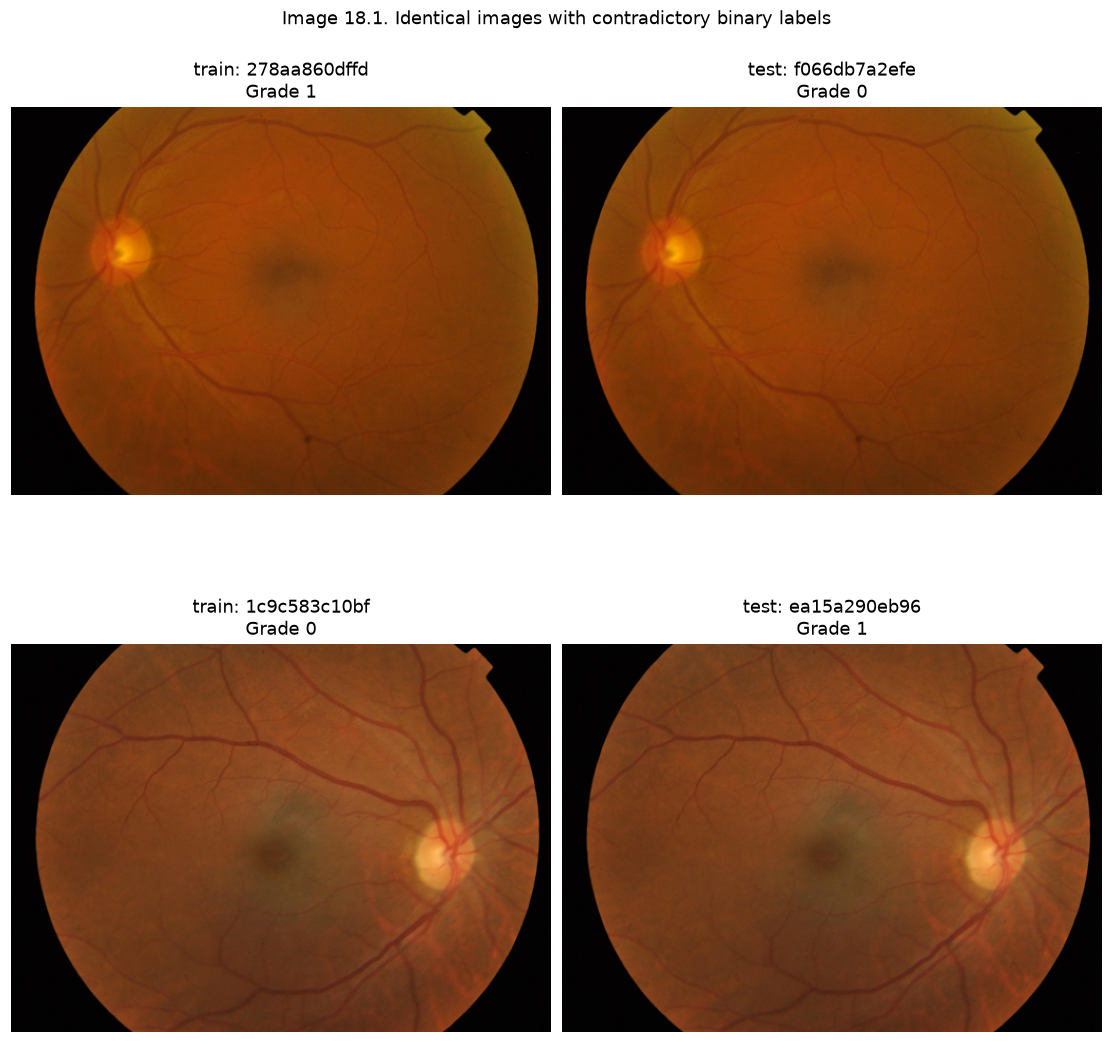

In [9]:
from PIL import Image

conflicts = cross.loc[cross["diagnosis_a"].gt(0) != cross["diagnosis_b"].gt(0)]
if conflicts.empty:
    print("No cross-split exact duplicates with conflicting binary labels.")
else:
    fig, axes = plt.subplots(len(conflicts), 2, figsize=(10, 5 * len(conflicts)), squeeze=False, layout="constrained")
    for row_axes, row in zip(axes, conflicts.itertuples()):
        for ax, side in zip(row_axes, ["a", "b"]):
            with Image.open(project_root / getattr(row, f"path_{side}")) as im:
                preview = im.convert("RGB")
                preview.thumbnail((512, 512))
                ax.imshow(preview)
            ax.set_title(f"{getattr(row, f'split_{side}')}: {getattr(row, f'id_{side}')}\nGrade {getattr(row, f'diagnosis_{side}')}")
            ax.axis("off")
    fig.suptitle("Image 18.1. Identical images with contradictory binary labels")
    fig.savefig(output_dir / "image_18_1_conflicting_duplicates.png", dpi=180, bbox_inches="tight")
    plt.show()


**Image 18.2. First six perceptual-hash candidates for visual review**

These examples are sorted by hash distance and identifiers, not by model performance. They are not automatically removed or relabeled.


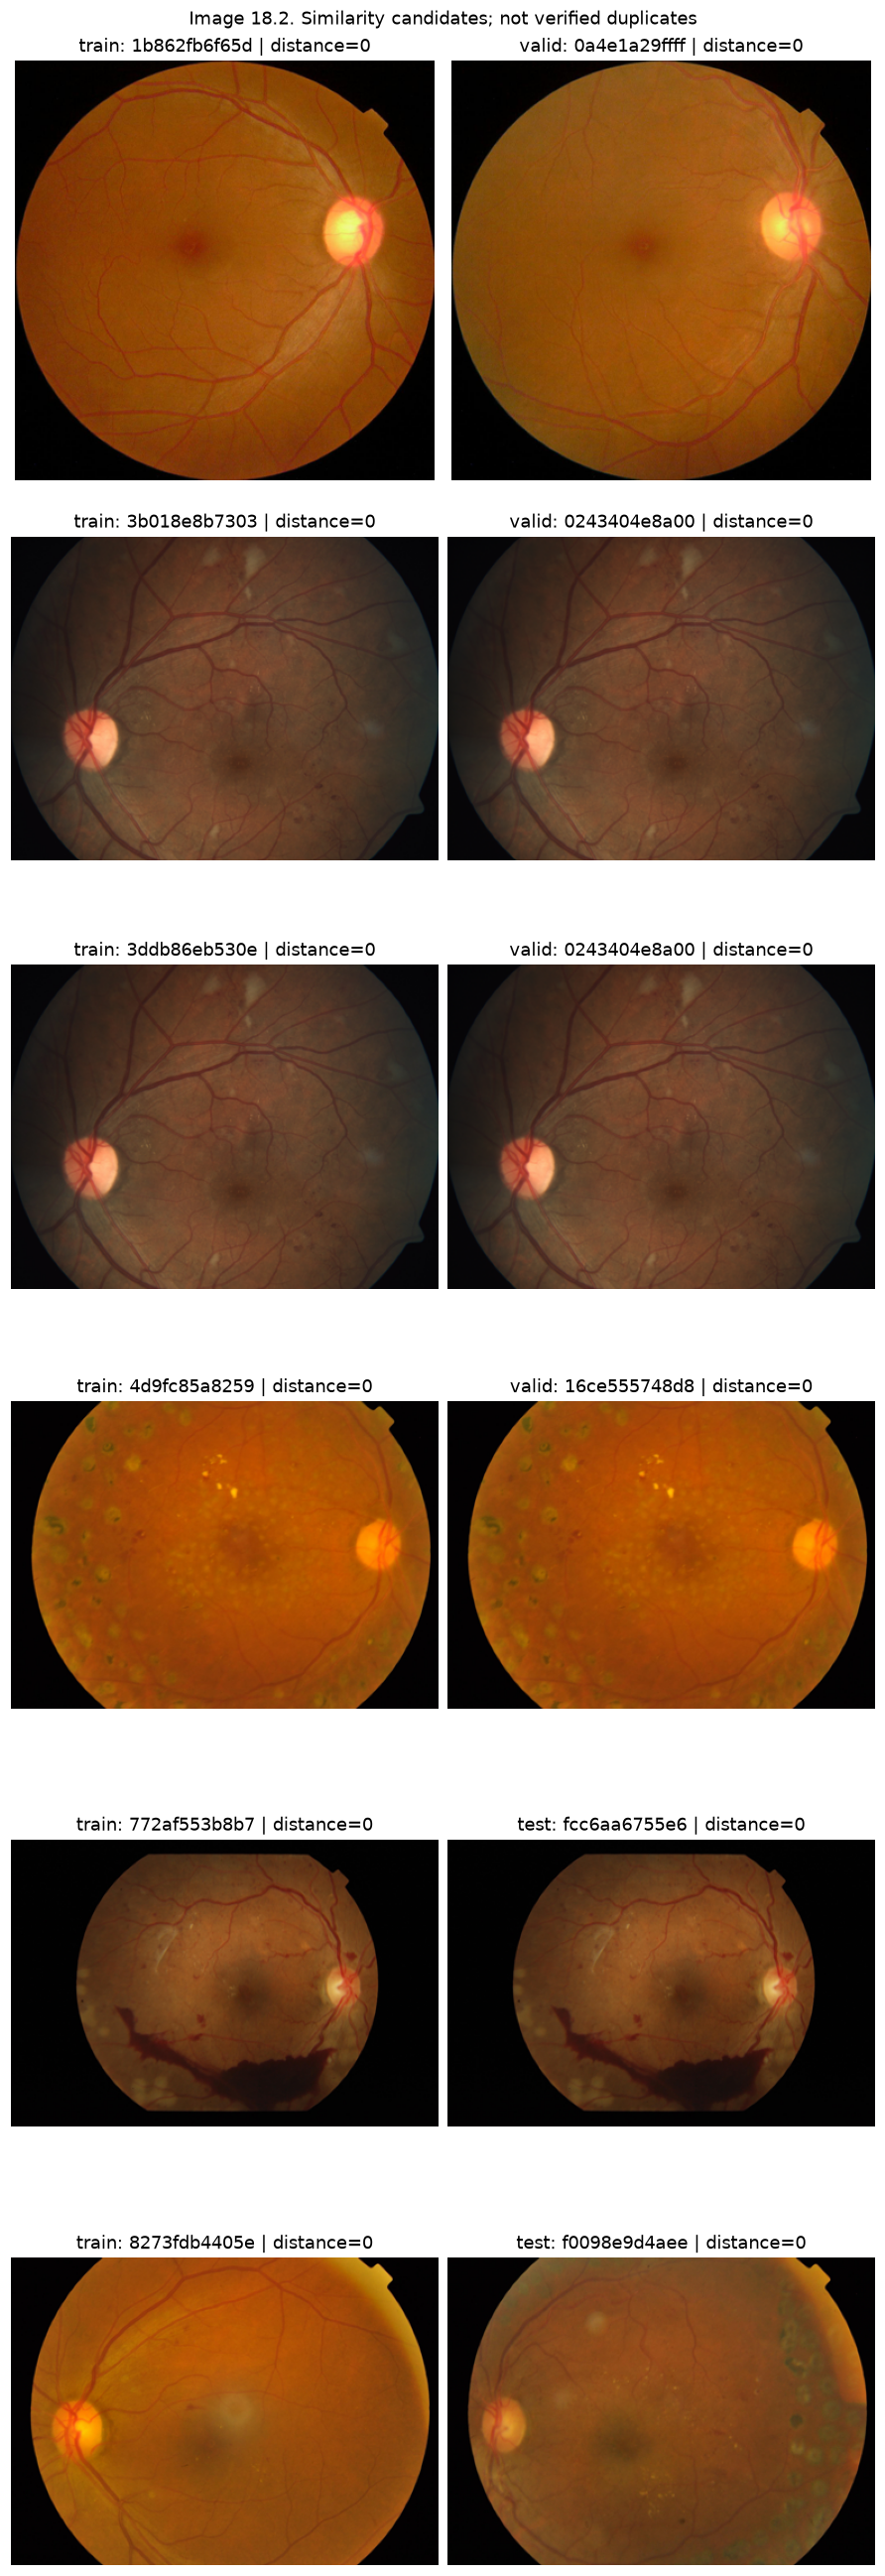

In [10]:
preview_pairs = similar.head(6)
if preview_pairs.empty:
    print("No perceptual-hash candidates at this cutoff.")
else:
    fig, axes = plt.subplots(len(preview_pairs), 2, figsize=(8, 4 * len(preview_pairs)), squeeze=False, layout="constrained")
    for row_axes, row in zip(axes, preview_pairs.itertuples()):
        for ax, side in zip(row_axes, ["a", "b"]):
            with Image.open(project_root / getattr(row, f"path_{side}")) as im:
                preview = im.convert("RGB")
                preview.thumbnail((384, 384))
                ax.imshow(preview)
            ax.set_title(f"{getattr(row, f'split_{side}')}: {getattr(row, f'id_{side}')} | distance={row.hamming_distance}")
            ax.axis("off")
    fig.suptitle("Image 18.2. Similarity candidates; not verified duplicates")
    fig.savefig(output_dir / "image_18_2_similarity_candidates.png", dpi=150, bbox_inches="tight")
    plt.show()


## Interpretation and evaluation protocol

The historical pipeline selects the best epoch using validation F1. Architecture comparisons also consulted the same test set, so that set is not a fresh final holdout. Patient-level separation is unverified.

Confirmed cross-split copies mean the historical scores must be presented as preliminary internal results. Before claiming final performance, group duplicate images before splitting, resolve or quarantine conflicting-label groups, review similarity candidates, and retrain from initialization. Removing copies from the test table alone does not undo validation leakage or prior model selection.

Methodological reference: [scikit-learn: data leakage](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).
